In [7]:
!zip -r resunet_GLaS_mod_2_outputs.zip /content/resunet_GLaS_mod2_fixedkernel_outputs

  adding: content/resunet_GLaS_mod2_fixedkernel_outputs/ (stored 0%)
  adding: content/resunet_GLaS_mod2_fixedkernel_outputs/validation_metrics_bar.png (deflated 21%)
  adding: content/resunet_GLaS_mod2_fixedkernel_outputs/test_metrics_bar.png (deflated 22%)
  adding: content/resunet_GLaS_mod2_fixedkernel_outputs/dataset_split_manifest.csv (deflated 93%)
  adding: content/resunet_GLaS_mod2_fixedkernel_outputs/validation_metrics_summary.csv (deflated 39%)
  adding: content/resunet_GLaS_mod2_fixedkernel_outputs/training_iou.png (deflated 10%)
  adding: content/resunet_GLaS_mod2_fixedkernel_outputs/final_resunet_mod2_fixedkernel.weights.h5 (deflated 9%)
  adding: content/resunet_GLaS_mod2_fixedkernel_outputs/test_metrics_summary.csv (deflated 39%)
  adding: content/resunet_GLaS_mod2_fixedkernel_outputs/validation_metrics_per_image.csv (deflated 51%)
  adding: content/resunet_GLaS_mod2_fixedkernel_outputs/test_metrics_per_image.csv (deflated 51%)
  adding: content/resunet_GLaS_mod2_fixedke

In [2]:
!unzip -q /content/GLaS.zip -d /content/

TensorFlow: 2.21.0
Visible GPU(s): [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Dataset root: /content/Warwick_QU_Dataset
Output directory: /content/resunet_GLaS_mod2_fixedkernel_outputs
Using the dataset's existing splits; no samples were reallocated.
Train       :  133 images
Validation  :   16 images
Test        :   16 images
Total paired images: 165
Saved split manifest: /content/resunet_GLaS_mod2_fixedkernel_outputs/dataset_split_manifest.csv


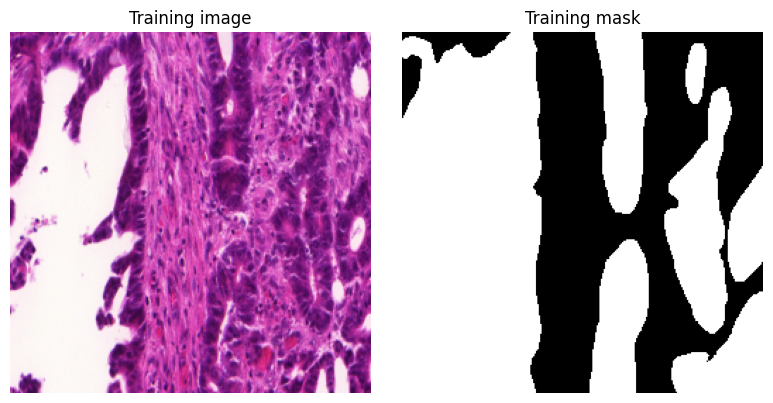

In [3]:
import os
import random
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

SEED = 42
IMG_SIZE = (256, 256)
BATCH_SIZE = 2
EPOCHS = 50
LEARNING_RATE = 1e-4
BOUNDARY_TOLERANCE_PX = 2
PREDICTION_THRESHOLD = 0.5

# Dataset is already extracted in Google Colab.
DATASET_ROOT = Path("/content/Warwick_QU_Dataset")
TRAIN_IMAGE_DIR = DATASET_ROOT / "train" / "img"
TRAIN_MASK_DIR = DATASET_ROOT / "train" / "mask"
VAL_IMAGE_DIR = DATASET_ROOT / "val" / "img"
VAL_MASK_DIR = DATASET_ROOT / "val" / "mask"
TEST_IMAGE_DIR = DATASET_ROOT / "test" / "img"
TEST_MASK_DIR = DATASET_ROOT / "test" / "mask"

OUTPUT_DIR = Path("/content/resunet_GLaS_mod2_fixedkernel_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for directory, label in (
    (TRAIN_IMAGE_DIR, "TRAIN_IMAGE_DIR"),
    (TRAIN_MASK_DIR, "TRAIN_MASK_DIR"),
    (VAL_IMAGE_DIR, "VAL_IMAGE_DIR"),
    (VAL_MASK_DIR, "VAL_MASK_DIR"),
    (TEST_IMAGE_DIR, "TEST_IMAGE_DIR"),
    (TEST_MASK_DIR, "TEST_MASK_DIR"),
):
    if not directory.is_dir():
        raise FileNotFoundError(f"{label} does not exist: {directory}")

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as exc:
        print("GPU memory growth setting:", exc)

print("TensorFlow:", tf.__version__)
print("Visible GPU(s):", tf.config.list_physical_devices("GPU"))
print("Dataset root:", DATASET_ROOT)
print("Output directory:", OUTPUT_DIR)


VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
AUTOTUNE = tf.data.AUTOTUNE


def get_pairs(image_dir, mask_dir):
    valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

    def collect_files(directory, is_mask=False):
        files = {}

        if not os.path.isdir(directory):
            raise FileNotFoundError(f"Directory not found: {directory}")

        for name in sorted(os.listdir(directory)):
            path = os.path.join(directory, name)

            if not os.path.isfile(path):
                continue

            stem, ext = os.path.splitext(name)
            if ext.lower() not in valid_extensions:
                continue

            # Warwick QU masks may use names such as testa_17_anno.png.
            if is_mask and stem.lower().endswith("_anno"):
                stem = stem[:-5]

            key = stem.casefold()
            if key in files:
                raise ValueError(f"Duplicate filename after normalization: {name}")

            files[key] = path

        return files

    image_files = collect_files(image_dir)
    mask_files = collect_files(mask_dir, is_mask=True)

    missing_masks = sorted(set(image_files) - set(mask_files))
    orphan_masks = sorted(set(mask_files) - set(image_files))

    if missing_masks or orphan_masks:
        raise ValueError(
            f"Image/mask pairing is incomplete in {image_dir} and {mask_dir}.\n"
            f"Images without masks: {missing_masks[:10]}\n"
            f"Masks without images: {orphan_masks[:10]}"
        )

    return [
        (image_files[key], mask_files[key])
        for key in sorted(image_files)
    ]


def _decode_path(path):
    if isinstance(path, np.ndarray):
        path = path.item()
    return os.fsdecode(path)


def load_image_mask(img_path, mask_path):
    img_path = _decode_path(img_path)
    mask_path = _decode_path(mask_path)

    image = cv2.imread(img_path, cv2.IMREAD_COLOR)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    if image is None:
        raise ValueError(f"Could not read image: {img_path}")
    if mask is None:
        raise ValueError(f"Could not read mask: {mask_path}")

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(
        image, (IMG_SIZE[1], IMG_SIZE[0]), interpolation=cv2.INTER_AREA
    ).astype(np.float32) / 255.0

    mask = cv2.resize(
        mask, (IMG_SIZE[1], IMG_SIZE[0]), interpolation=cv2.INTER_NEAREST
    )
    threshold = 0 if mask.max(initial=0) <= 1 else 127
    mask = (mask > threshold).astype(np.float32)[..., np.newaxis]

    return image, mask


def tf_load_image_mask(img_path, mask_path):
    image, mask = tf.numpy_function(
        func=load_image_mask,
        inp=[img_path, mask_path],
        Tout=[tf.float32, tf.float32],
    )
    image.set_shape([IMG_SIZE[0], IMG_SIZE[1], 3])
    mask.set_shape([IMG_SIZE[0], IMG_SIZE[1], 1])
    return image, mask


def augment(image, mask):
    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_left_right(image)
        mask = tf.image.flip_left_right(mask)
    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_up_down(image)
        mask = tf.image.flip_up_down(mask)
    return image, mask


def make_dataset(split_pairs, training=False):
    if not split_pairs:
        raise ValueError("Cannot create a dataset from an empty split.")

    image_paths = [pair[0] for pair in split_pairs]
    mask_paths = [pair[1] for pair in split_pairs]
    dataset = tf.data.Dataset.from_tensor_slices((image_paths, mask_paths))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(split_pairs),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    dataset = dataset.map(tf_load_image_mask, num_parallel_calls=AUTOTUNE)
    if training:
        dataset = dataset.map(augment, num_parallel_calls=AUTOTUNE)

    options = tf.data.Options()
    options.experimental_deterministic = True
    return dataset.with_options(options).batch(BATCH_SIZE).prefetch(AUTOTUNE)


# Use the dataset's existing train/val/test folders. No re-splitting is performed.
train_pairs = get_pairs(TRAIN_IMAGE_DIR, TRAIN_MASK_DIR)
val_pairs = get_pairs(VAL_IMAGE_DIR, VAL_MASK_DIR)
test_pairs = get_pairs(TEST_IMAGE_DIR, TEST_MASK_DIR)

if not train_pairs or not val_pairs or not test_pairs:
    raise ValueError(
        "Each existing split must contain at least one correctly paired image and mask. "
        f"Found train={len(train_pairs)}, val={len(val_pairs)}, test={len(test_pairs)}."
    )

split_pairs = {
    "train": train_pairs,
    "validation": val_pairs,
    "test": test_pairs,
}
split_keys = {
    name: {os.path.realpath(image_path) for image_path, _ in split}
    for name, split in split_pairs.items()
}
if any(
    split_keys[a] & split_keys[b]
    for a, b in (("train", "validation"), ("train", "test"), ("validation", "test"))
):
    raise AssertionError(
        "The provided dataset has overlapping image paths between splits. "
        "Check that train, val, and test point to different folders."
    )

# Keep a combined list for existing evaluation/reporting code that uses `pairs`.
pairs = train_pairs + val_pairs + test_pairs

manifest_rows = [
    {
        "split": split_name,
        "image": image_path,
        "mask": mask_path,
        "image_filename": os.path.basename(image_path),
    }
    for split_name, split in split_pairs.items()
    for image_path, mask_path in split
]
manifest_path = os.path.join(OUTPUT_DIR, "dataset_split_manifest.csv")
pd.DataFrame(manifest_rows).to_csv(manifest_path, index=False)

train_ds = make_dataset(train_pairs, training=True)
val_ds = make_dataset(val_pairs, training=False)
test_ds = make_dataset(test_pairs, training=False)

print("Using the dataset's existing splits; no samples were reallocated.")
for split_name, split in split_pairs.items():
    print(f"{split_name.title():12s}: {len(split):4d} images")
print(f"Total paired images: {len(pairs)}")
print(f"Saved split manifest: {manifest_path}")

example_image, example_mask = load_image_mask(*train_pairs[0])
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(example_image)
axes[0].set_title("Training image")
axes[1].imshow(example_mask[..., 0], cmap="gray")
axes[1].set_title("Training mask")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

In [4]:
def residual_block_initial(x, filters, strides=(1, 1), name='res_initial'):
    y = tf.keras.layers.Conv2D(filters, 3, strides=strides[0], padding='same', use_bias=False, kernel_initializer='he_normal', name=f'{name}_conv1')(x)
    y = tf.keras.layers.BatchNormalization(name=f'{name}_bn1')(y)
    y = tf.keras.layers.Activation('relu', name=f'{name}_relu1')(y)
    y = tf.keras.layers.Conv2D(filters, 3, strides=strides[1], padding='same', use_bias=False, kernel_initializer='he_normal', name=f'{name}_conv2')(y)
    shortcut = tf.keras.layers.Conv2D(filters, 1, strides=strides[0], padding='same', use_bias=False, kernel_initializer='he_normal', name=f'{name}_shortcut_conv')(x)
    shortcut = tf.keras.layers.BatchNormalization(name=f'{name}_shortcut_bn')(shortcut)
    return tf.keras.layers.Add(name=f'{name}_add')([shortcut, y])

def residual_block(x, filters, strides=(1, 1), name='res_block'):
    input_channels = x.shape[-1]
    y = tf.keras.layers.BatchNormalization(name=f'{name}_bn1')(x)
    y = tf.keras.layers.Activation('relu', name=f'{name}_relu1')(y)
    y = tf.keras.layers.Conv2D(filters, 3, strides=strides[0], padding='same', use_bias=False, kernel_initializer='he_normal', name=f'{name}_conv1')(y)
    y = tf.keras.layers.BatchNormalization(name=f'{name}_bn2')(y)
    y = tf.keras.layers.Activation('relu', name=f'{name}_relu2')(y)
    y = tf.keras.layers.Conv2D(filters, 3, strides=strides[1], padding='same', use_bias=False, kernel_initializer='he_normal', name=f'{name}_conv2')(y)
    if strides[0] != 1 or input_channels != filters:
        shortcut = tf.keras.layers.Conv2D(filters, 1, strides=strides[0], padding='same', use_bias=False, kernel_initializer='he_normal', name=f'{name}_shortcut_conv')(x)
        shortcut = tf.keras.layers.BatchNormalization(name=f'{name}_shortcut_bn')(shortcut)
    else:
        shortcut = x
    return tf.keras.layers.Add(name=f'{name}_add')([shortcut, y])

@tf.keras.utils.register_keras_serializable(package='RockSegmentation')
class FixedKernelLayer(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        kwargs['trainable'] = False
        super().__init__(**kwargs)

    def build(self, input_shape):
        channels = int(input_shape[-1])
        sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32)
        sobel_y = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=np.float32)
        laplacian = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=np.float32)
        def depthwise_kernel(base_kernel):
            kernel = np.zeros((3, 3, channels, 1), dtype=np.float32)
            for channel in range(channels):
                kernel[:, :, channel, 0] = base_kernel
            return tf.constant(kernel, dtype=tf.float32)
        self.k_sobel_x = depthwise_kernel(sobel_x)
        self.k_sobel_y = depthwise_kernel(sobel_y)
        self.k_laplacian = depthwise_kernel(laplacian)
        super().build(input_shape)

    def call(self, x):
        sx = tf.nn.depthwise_conv2d(x, self.k_sobel_x, strides=[1, 1, 1, 1], padding='SAME')
        sy = tf.nn.depthwise_conv2d(x, self.k_sobel_y, strides=[1, 1, 1, 1], padding='SAME')
        lap = tf.nn.depthwise_conv2d(x, self.k_laplacian, strides=[1, 1, 1, 1], padding='SAME')
        return tf.concat([sx, sy, lap], axis=-1)

def merge_with_fixed_kernels(feat, filters, prefix):
    fixed_response = FixedKernelLayer(name=f'{prefix}_fixed_kernel')(feat)
    merged = tf.keras.layers.Concatenate(name=f'{prefix}_raw_edge_concat')([feat, fixed_response])
    merged = tf.keras.layers.Conv2D(filters, 1, padding='same', use_bias=False, kernel_initializer='he_normal', name=f'{prefix}_compress')(merged)
    return tf.keras.layers.ReLU(name=f'{prefix}_compress_relu')(merged)

def fixed_kernel_decoder_block(x, skip, skip_fixed, filters, name):
    x = tf.keras.layers.UpSampling2D(size=(2, 2), interpolation='bilinear', name=f'{name}_upsample')(x)
    x = tf.keras.layers.Conv2D(filters, 3, padding='same', use_bias=False, kernel_initializer='he_normal', name=f'{name}_up_projection')(x)
    x = tf.keras.layers.Concatenate(name=f'{name}_raw_fixed_concat')([x, skip, skip_fixed])
    return residual_block(x, filters, name=f'{name}_residual')

def build_resunet_fixedkernel(input_shape=(256, 256, 3), filters=(64, 128, 256, 512)):
    inputs = tf.keras.Input(shape=input_shape, name='image')
    e0 = residual_block_initial(inputs, filters[0], name='encoder_block0')
    e1 = residual_block(e0, filters[1], strides=(2, 1), name='encoder_block1')
    e2 = residual_block(e1, filters[2], strides=(2, 1), name='encoder_block2')
    e3 = residual_block(e2, filters[3], strides=(2, 1), name='encoder_block3')
    e0_fixed = merge_with_fixed_kernels(e0, filters[0], 'skip_e0')
    e1_fixed = merge_with_fixed_kernels(e1, filters[1], 'skip_e1')
    e2_fixed = merge_with_fixed_kernels(e2, filters[2], 'skip_e2')
    e3_fixed = merge_with_fixed_kernels(e3, filters[3], 'skip_e3')
    bridge = residual_block(e3, filters[3] * 2, strides=(2, 1), name='bridge')
    d3 = fixed_kernel_decoder_block(bridge, e3, e3_fixed, filters[3], 'decoder_block3')
    d2 = fixed_kernel_decoder_block(d3, e2, e2_fixed, filters[2], 'decoder_block2')
    d1 = fixed_kernel_decoder_block(d2, e1, e1_fixed, filters[1], 'decoder_block1')
    d0 = fixed_kernel_decoder_block(d1, e0, e0_fixed, filters[0], 'decoder_block0')
    logits = tf.keras.layers.Conv2D(1, 1, padding='same', activation=None, name='segmentation_logits')(d0)
    return tf.keras.Model(inputs=inputs, outputs=logits, name='ResUNet_FixedKernel')

def binary_from_logits(y_true, y_pred):
    return tf.cast(y_true >= 0.5, tf.float32), tf.cast(y_pred >= 0.0, tf.float32)

def binary_accuracy_logits(y_true, y_pred):
    y_true, y_pred = binary_from_logits(y_true, y_pred)
    return tf.reduce_mean(tf.cast(tf.equal(y_true, y_pred), tf.float32))

def dice_coef_logits(y_true, y_pred, smooth=1e-7):
    y_true, y_pred = binary_from_logits(y_true, y_pred)
    y_true, y_pred = tf.reshape(y_true, [-1]), tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true * y_pred)
    return (2.0 * intersection + smooth) / (tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + smooth)

def iou_coef_logits(y_true, y_pred, smooth=1e-7):
    y_true, y_pred = binary_from_logits(y_true, y_pred)
    y_true, y_pred = tf.reshape(y_true, [-1]), tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true * y_pred)
    union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) - intersection
    return (intersection + smooth) / (union + smooth)

PAPER_FILTERS = (64, 128, 256, 512)
model = build_resunet_fixedkernel(input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3), filters=PAPER_FILTERS)
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE), loss=tf.keras.losses.BinaryCrossentropy(from_logits=True), metrics=[binary_accuracy_logits, dice_coef_logits, iou_coef_logits])
model.summary()

Model: "ResUNet_FixedKernel"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 256, 256,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_con… │ (None, 256, 256,  │      1,728 │ image[0][0]       │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_bn1  │ (None, 256, 256,  │        256 │ encoder_block0_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_sho… │ (None, 256, 256,  │        192 │ image[0][0]       │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_rel… │ (None, 256, 256,  │          0 │ encoder_block0_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_sho… │ (None, 256, 256,  │        256 │ encoder_block0_s… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_con… │ (None, 256, 256,  │     36,864 │ encoder_block0_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_add  │ (None, 256, 256,  │          0 │ encoder_block0_s… │
│ (Add)               │ 64)               │            │ encoder_block0_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_bn1  │ (None, 256, 256,  │        256 │ encoder_block0_a… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_rel… │ (None, 256, 256,  │          0 │ encoder_block1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_con… │ (None, 128, 128,  │     73,728 │ encoder_block1_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_bn2  │ (None, 128, 128,  │        512 │ encoder_block1_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_sho… │ (None, 128, 128,  │      8,192 │ encoder_block0_a… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_rel… │ (None, 128, 128,  │          0 │ encoder_block1_b… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_sho… │ (None, 128, 128,  │        512 │ encoder_block1_s… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_con… │ (None, 128, 128,  │    147,456 │ encoder_block1_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_add  │ (None, 128, 128,  │          0 │ encoder_block1_s

 Total params: 40,812,481 (155.69 MB)

 Trainable params: 40,793,025 (155.61 MB)

 Non-trainable params: 19,456 (76.00 KB)

Epoch 1/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - binary_accuracy_logits: 0.6533 - dice_coef_logits: 0.6375 - iou_coef_logits: 0.4812 - loss: 0.7048   
Epoch 1: val_dice_coef_logits improved from None to 0.00084, saving model to /content/resunet_GLaS_mod2_fixedkernel_outputs/best_resunet_mod2_fixedkernel.weights.h5

Epoch 1: finished saving model to /content/resunet_GLaS_mod2_fixedkernel_outputs/best_resunet_mod2_fixedkernel.weights.h5
67/67 ━━━━━━━━━━━━━━━━━━━━ 244s 2s/step - binary_accuracy_logits: 0.7126 - dice_coef_logits: 0.7077 - iou_coef_logits: 0.5580 - loss: 0.5953 - val_binary_accuracy_logits: 0.5162 - val_dice_coef_logits: 8.3844e-04 - val_iou_coef_logits: 4.1962e-04 - val_loss: 7.7609 - learning_rate: 1.0000e-04
Epoch 2/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 374ms/step - binary_accuracy_logits: 0.7792 - dice_coef_logits: 0.7787 - iou_coef_logits: 0.6449 - loss: 0.4768
Epoch 2: val_dice_coef_logits improved from 0.00084 to 0.28827, saving model to /content/resunet_GLaS_mod2_fixed

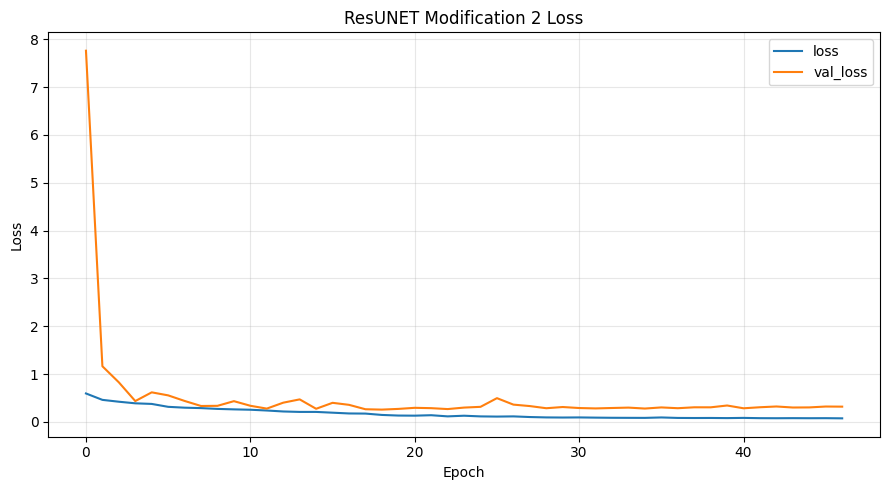

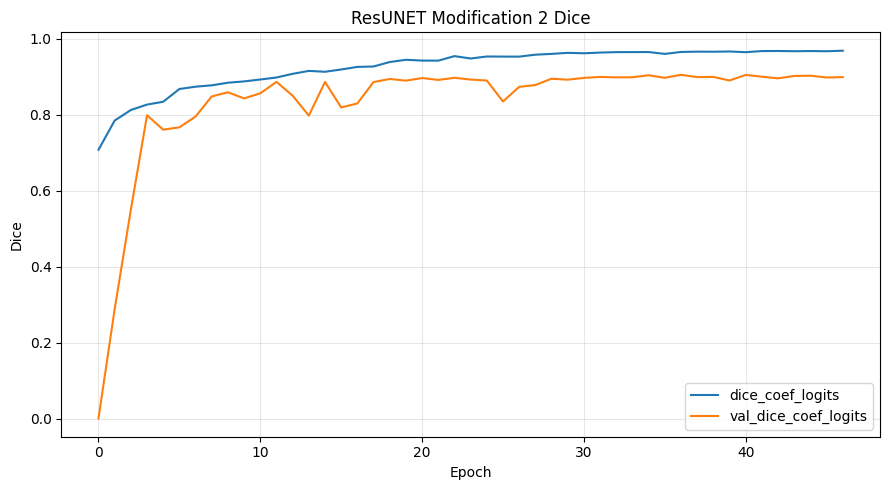

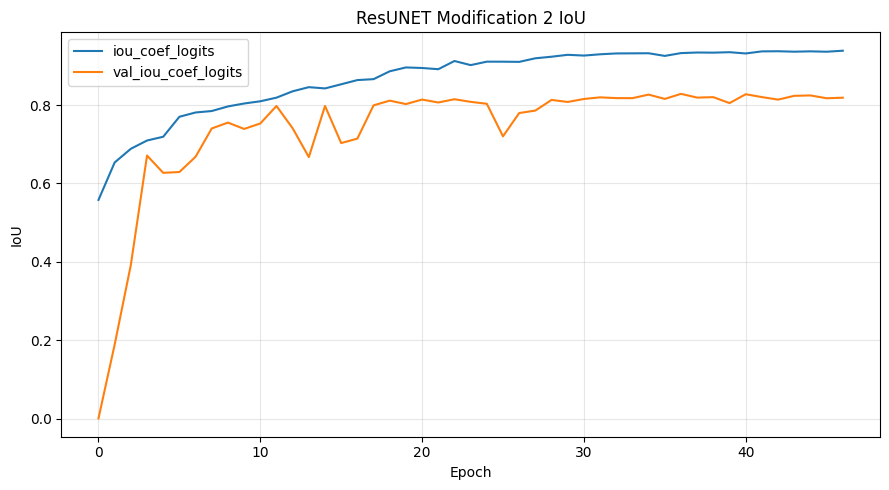

Best weights: /content/resunet_GLaS_mod2_fixedkernel_outputs/best_resunet_mod2_fixedkernel.weights.h5
Final weights: /content/resunet_GLaS_mod2_fixedkernel_outputs/final_resunet_mod2_fixedkernel.weights.h5
Training outputs: /content/resunet_GLaS_mod2_fixedkernel_outputs


In [5]:
BEST_WEIGHTS_PATH = os.path.join(OUTPUT_DIR, 'best_resunet_mod2_fixedkernel.weights.h5')
FINAL_WEIGHTS_PATH = os.path.join(OUTPUT_DIR, 'final_resunet_mod2_fixedkernel.weights.h5')

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(filepath=BEST_WEIGHTS_PATH, monitor='val_dice_coef_logits', mode='max', save_best_only=True, save_weights_only=True, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor='val_dice_coef_logits', mode='max', patience=10, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_dice_coef_logits', mode='max', factor=0.5, patience=4, min_lr=1e-6, verbose=1),
    tf.keras.callbacks.CSVLogger(os.path.join(OUTPUT_DIR, 'training_log.csv'))
]

history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks, verbose=1)
if not os.path.isfile(BEST_WEIGHTS_PATH):
    raise FileNotFoundError(f'Best checkpoint was not created: {BEST_WEIGHTS_PATH}')
model.load_weights(BEST_WEIGHTS_PATH)
model.save_weights(FINAL_WEIGHTS_PATH)
pd.DataFrame(history.history).to_csv(os.path.join(OUTPUT_DIR, 'training_history.csv'), index_label='epoch')
for metric_pairs, title, ylabel, filename in [
    (('loss', 'val_loss'), 'ResUNET Modification 2 Loss', 'Loss', 'training_loss.png'),
    (('dice_coef_logits', 'val_dice_coef_logits'), 'ResUNET Modification 2 Dice', 'Dice', 'training_dice.png'),
    (('iou_coef_logits', 'val_iou_coef_logits'), 'ResUNET Modification 2 IoU', 'IoU', 'training_iou.png')
]:
    plt.figure(figsize=(9, 5))
    for key in metric_pairs:
        if key in history.history:
            plt.plot(history.history[key], label=key)
    plt.title(title)
    plt.xlabel('Epoch')
    plt.ylabel(ylabel)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=160, bbox_inches='tight')
    plt.show()
print('Best weights:', BEST_WEIGHTS_PATH)
print('Final weights:', FINAL_WEIGHTS_PATH)
print('Training outputs:', OUTPUT_DIR)

Validation 1/16: testA_1.png
Validation 2/16: testA_10.png
Validation 3/16: testA_11.png
Validation 4/16: testA_12.png
Validation 5/16: testA_13.png
Validation 6/16: testA_14.png
Validation 7/16: testA_15.png
Validation 8/16: testA_16.png
Validation 9/16: testA_2.png
Validation 10/16: testA_3.png
Validation 11/16: testA_4.png
Validation 12/16: testA_5.png
Validation 13/16: testA_6.png
Validation 14/16: testA_7.png
Validation 15/16: testA_8.png
Validation 16/16: testA_9.png


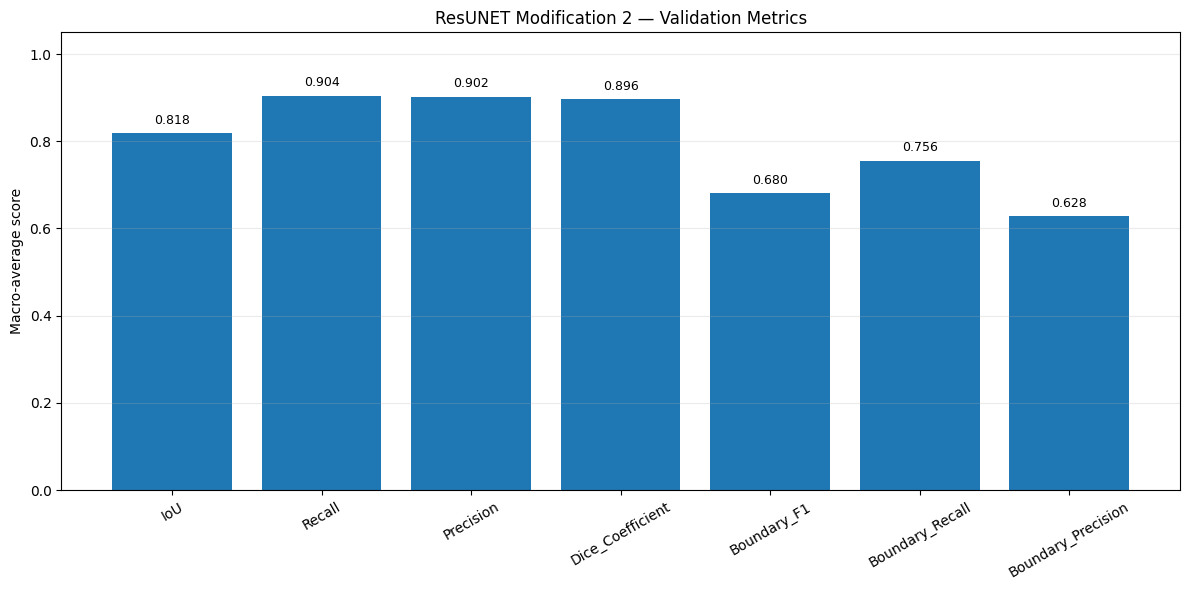


Validation macro-average metrics over 16 images
IoU                   : 0.8181 ± 0.1083
Recall                : 0.9040 ± 0.1078
Precision             : 0.9019 ± 0.0857
Dice_Coefficient      : 0.8962 ± 0.0682
Boundary_F1           : 0.6804 ± 0.1234
Boundary_Recall       : 0.7559 ± 0.0948
Boundary_Precision    : 0.6283 ± 0.1549
Test 1/16: testB_1.png
Test 2/16: testB_10.png
Test 3/16: testB_11.png
Test 4/16: testB_12.png
Test 5/16: testB_13.png
Test 6/16: testB_14.png
Test 7/16: testB_15.png
Test 8/16: testB_16.png
Test 9/16: testB_2.png
Test 10/16: testB_3.png
Test 11/16: testB_4.png
Test 12/16: testB_5.png
Test 13/16: testB_6.png
Test 14/16: testB_7.png
Test 15/16: testB_8.png
Test 16/16: testB_9.png


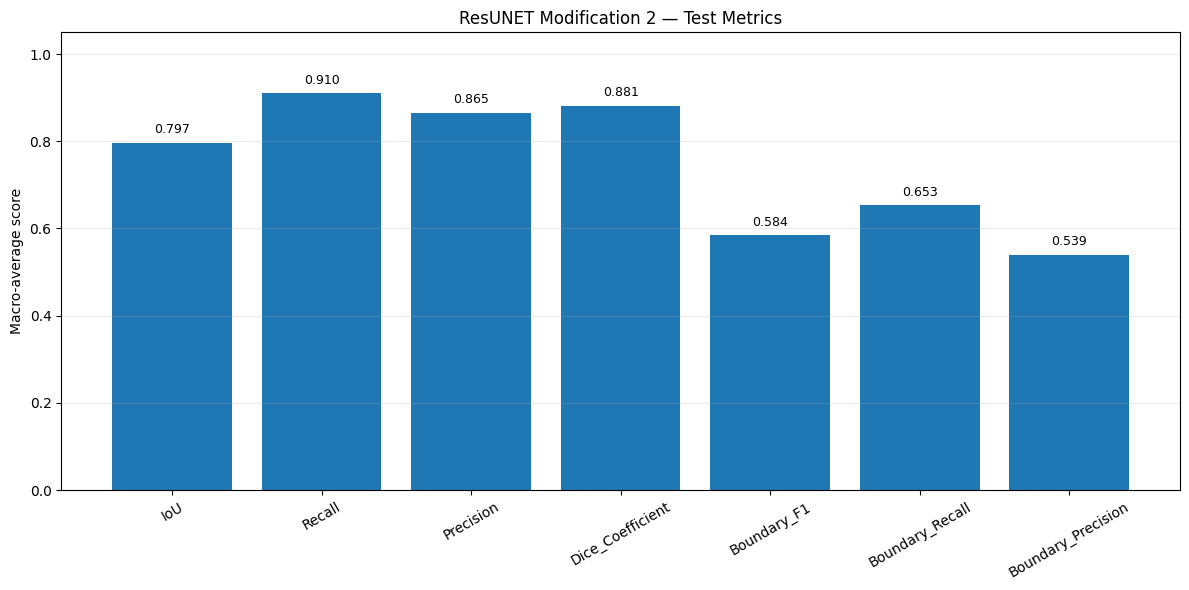


Test macro-average metrics over 16 images
IoU                   : 0.7966 ± 0.1254
Recall                : 0.9103 ± 0.1032
Precision             : 0.8652 ± 0.0984
Dice_Coefficient      : 0.8814 ± 0.0816
Boundary_F1           : 0.5843 ± 0.2045
Boundary_Recall       : 0.6531 ± 0.2174
Boundary_Precision    : 0.5394 ± 0.2065

Test predicted masks: /content/resunet_GLaS_mod2_fixedkernel_outputs/test_predicted_masks
Test comparison previews: /content/resunet_GLaS_mod2_fixedkernel_outputs/test_prediction_previews
Saved test mask count: 16
Dataset manifest: /content/resunet_GLaS_mod2_fixedkernel_outputs/dataset_split_manifest.csv
All artifacts: /content/resunet_GLaS_mod2_fixedkernel_outputs


In [6]:
METRIC_COLUMNS = ['IoU', 'Recall', 'Precision', 'Dice_Coefficient', 'Boundary_F1', 'Boundary_Recall', 'Boundary_Precision']

def safe_divide(numerator, denominator):
    return float(numerator / denominator) if denominator else 0.0

def binary_segmentation_metrics(y_true, y_pred):
    gt = np.asarray(y_true, dtype=bool)
    pred = np.asarray(y_pred, dtype=bool)
    tp = int(np.logical_and(gt, pred).sum())
    fp = int(np.logical_and(~gt, pred).sum())
    fn = int(np.logical_and(gt, ~pred).sum())
    precision = safe_divide(tp, tp + fp)
    recall = safe_divide(tp, tp + fn)
    iou = safe_divide(tp, tp + fp + fn)
    dice = safe_divide(2 * tp, 2 * tp + fp + fn)
    gt_u8 = gt.astype(np.uint8)
    pred_u8 = pred.astype(np.uint8)
    contour_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    gt_boundary = (gt_u8 - cv2.erode(gt_u8, contour_kernel, iterations=1)).astype(bool)
    pred_boundary = (pred_u8 - cv2.erode(pred_u8, contour_kernel, iterations=1)).astype(bool)
    tolerance_size = 2 * BOUNDARY_TOLERANCE_PX + 1
    tolerance_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (tolerance_size, tolerance_size))
    gt_dilated = cv2.dilate(gt_boundary.astype(np.uint8), tolerance_kernel, iterations=1).astype(bool)
    pred_dilated = cv2.dilate(pred_boundary.astype(np.uint8), tolerance_kernel, iterations=1).astype(bool)
    boundary_precision = safe_divide(int(np.logical_and(pred_boundary, gt_dilated).sum()), int(pred_boundary.sum()))
    boundary_recall = safe_divide(int(np.logical_and(gt_boundary, pred_dilated).sum()), int(gt_boundary.sum()))
    boundary_f1 = safe_divide(2 * boundary_precision * boundary_recall, boundary_precision + boundary_recall)
    return {'IoU': iou, 'Recall': recall, 'Precision': precision, 'Dice_Coefficient': dice, 'Boundary_F1': boundary_f1, 'Boundary_Recall': boundary_recall, 'Boundary_Precision': boundary_precision}

def evaluate_split(split_pairs, split_name, save_predictions=False):
    rows = []
    prediction_dir = os.path.join(OUTPUT_DIR, 'test_predicted_masks') if save_predictions else None
    preview_dir = os.path.join(OUTPUT_DIR, 'test_prediction_previews') if save_predictions else None
    if save_predictions:
        os.makedirs(prediction_dir, exist_ok=True)
        os.makedirs(preview_dir, exist_ok=True)
    for index, (image_path, mask_path) in enumerate(split_pairs, start=1):
        image, gt_mask = load_image_mask(image_path, mask_path)
        logits = model.predict(image[np.newaxis, ...], verbose=0)[0, ..., 0]
        pred_mask = tf.math.sigmoid(logits).numpy() >= PREDICTION_THRESHOLD
        gt_binary = gt_mask[..., 0] >= 0.5
        scores = binary_segmentation_metrics(gt_binary, pred_mask)
        rows.append({'image_name': Path(image_path).name, **scores})
        if save_predictions:
            stem = Path(image_path).stem
            mask_output_path = os.path.join(prediction_dir, f'{stem}_prediction.png')
            written = cv2.imwrite(mask_output_path, pred_mask.astype(np.uint8) * 255)
            if not written:
                raise IOError(f'Failed to save predicted mask: {mask_output_path}')
            overlay = image.copy()
            overlay[pred_mask] = 0.55 * overlay[pred_mask] + 0.45 * np.array([1.0, 0.0, 0.0])
            fig, axes = plt.subplots(1, 4, figsize=(14, 4))
            axes[0].imshow(image)
            axes[0].set_title('Image')
            axes[1].imshow(gt_binary, cmap='gray')
            axes[1].set_title('Ground truth')
            axes[2].imshow(pred_mask, cmap='gray')
            axes[2].set_title('Predicted mask')
            axes[3].imshow(np.clip(overlay, 0, 1))
            axes[3].set_title('Overlay')
            for ax in axes:
                ax.axis('off')
            fig.suptitle(Path(image_path).name)
            plt.tight_layout()
            fig.savefig(os.path.join(preview_dir, f'{stem}_comparison.png'), dpi=140, bbox_inches='tight')
            plt.close(fig)
        print(f'{split_name.title()} {index}/{len(split_pairs)}: {Path(image_path).name}')
    if not rows:
        raise RuntimeError(f'{split_name} split is empty.')
    result_df = pd.DataFrame(rows)
    summary_df = pd.DataFrame([{'metric': metric, 'macro_average': float(result_df[metric].mean()), 'std': float(result_df[metric].std(ddof=1)) if len(result_df) > 1 else 0.0, 'n_images': len(result_df)} for metric in METRIC_COLUMNS])
    result_df.to_csv(os.path.join(OUTPUT_DIR, f'{split_name}_metrics_per_image.csv'), index=False)
    summary_df.to_csv(os.path.join(OUTPUT_DIR, f'{split_name}_metrics_summary.csv'), index=False)
    fig, ax = plt.subplots(figsize=(12, 6))
    bars = ax.bar(summary_df['metric'], summary_df['macro_average'])
    ax.set_ylim(0, 1.05)
    ax.set_ylabel('Macro-average score')
    ax.set_title(f'ResUNET Modification 2 — {split_name.title()} Metrics')
    ax.tick_params(axis='x', labelrotation=30)
    ax.grid(axis='y', alpha=0.25)
    for bar, value in zip(bars, summary_df['macro_average']):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 0.015, f'{value:.3f}', ha='center', va='bottom', fontsize=9)
    plt.tight_layout()
    fig.savefig(os.path.join(OUTPUT_DIR, f'{split_name}_metrics_bar.png'), dpi=180, bbox_inches='tight')
    plt.show()
    print(f'\n{split_name.title()} macro-average metrics over {len(result_df)} images')
    for _, row in summary_df.iterrows():
        print(f"{row['metric']:<22}: {row['macro_average']:.4f} ± {row['std']:.4f}")
    return result_df, summary_df

val_results, val_summary = evaluate_split(val_pairs, 'validation', save_predictions=False)
test_results, test_summary = evaluate_split(test_pairs, 'test', save_predictions=True)
print('\nTest predicted masks:', os.path.join(OUTPUT_DIR, 'test_predicted_masks'))
print('Test comparison previews:', os.path.join(OUTPUT_DIR, 'test_prediction_previews'))
print('Saved test mask count:', len(list(Path(os.path.join(OUTPUT_DIR, 'test_predicted_masks')).glob('*_prediction.png'))))
print('Dataset manifest:', os.path.join(OUTPUT_DIR, 'dataset_split_manifest.csv'))
print('All artifacts:', OUTPUT_DIR)